# Toy time series - August 11, 2015
Plot the toy example time series data

In [34]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import os

toy_dir = os.path.join('..','..','toyExamples','synthesis')
ts_file = os.path.join(toy_dir,'TimeSeries.txt')
out_img = os.path.join(toy_dir, 'TimeSeries081115')

##Configure seaborn plotting defaults

In [19]:
sns.set() # Restore defaults
sns.set_palette('Set2', 6)
# Enlarge the text labels
sns.set_context('paper', font_scale=2)
sns.set_style('whitegrid')

## Load the time series

In [23]:
df = pd.read_csv(ts_file, sep='\t')

# Rename the columns
df.rename(columns={'0min':'0', '1min':'1', '2min':'2', '5min':'5'}, inplace=True)
# Melt the data frame so that condition names are listed in a single column and the phosphorylation levels are given in another
df = pd.melt(df, id_vars='Node', var_name='Time point (min)', value_name='Relative phosphorylation')

## Plot the time series

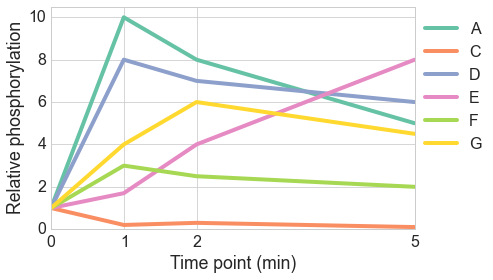

In [35]:
ax = sns.tsplot(time='Time point (min)', value='Relative phosphorylation', unit='Node', condition='Node', data=df, linewidth=4)

# Disable the legend title
lgd = ax.legend()
lgd.set_title('')

# Move the legend
lgd.set_bbox_to_anchor((1.22, 1))

ax.set_ylim(0, 10.5)
ax.set_xticks([0, 1, 2, 5])

# Save the figure as .png and .svg
plt.tight_layout()
plt.savefig(out_img + '.png', dpi=600, bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.savefig(out_img + '.svg', bbox_extra_artists=(lgd,), bbox_inches='tight')